# CS2: очистка данных и классификация kNN

Учебный проект на данных Counter-Strike 2 HLTV.

Источник: https://www.kaggle.com/datasets/victorpicinin/counter-strike-2-hltv-match-data



In [1]:
!pip install -q kagglehub pandas numpy matplotlib seaborn scikit-learn


In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("victorpicinin/counter-strike-2-hltv-match-data")

print("Path to dataset files:", path)

100%|██████████| 271k/271k [00:00<00:00, 31.5MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/victorpicinin/counter-strike-2-hltv-match-data/versions/2


In [3]:
import pandas as pd
import numpy as np

# Читаем файл из папки, которую скачал kagglehub
df = pd.read_csv(path + '/CS2_HLTV_MATCH_DATA2.csv', sep=';')

# Проверяем размер таблицы, типы столбцов и непустые значения
df.info()

# Показываем первые пять строк
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1202 entries, 0 to 1201
Columns: 158 entries, matchID to T2_player4_Rating 1.0
dtypes: float64(140), int64(2), object(16)
memory usage: 1.4+ MB


,matchID,team1,team2,map,team1_win,T1_mapwinrate,T2_mapwinrate,T1_player0_Total kills,T1_player0_Headshot %,T1_player0_Total deaths,...,T1_player0_Rating 2.0,T2_player0_Rating 2.0,T2_player1_Rating 1.0,Unnamed: 152,T1_player2_Rating 1.0,T1_player3_Rating 1.0,T1_player4_Rating 1.0,T2_player2_Rating 1.0,T2_player3_Rating 1.0,T2_player4_Rating 1.0
0,2368924,Case,Hype,Ancient,1,76.9%,0.0%,234.0,26.9%,171.0,...,1.25,1.06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2368925,AJF,Evolve,Vertigo,1,66.7%,0.0%,42.0,23.8%,46.0,...,0.92,1.32,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2368916,Space,IKLA,Anubis,1,27.3%,33.3%,159.0,59.1%,177.0,...,1.02,0.96,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2368916,Space,IKLA,Overpass,0,20.0%,28.6%,67.0,55.2%,88.0,...,0.87,0.96,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2368916,Space,IKLA,Mirage,0,41.7%,00.0%,166.0,57.8%,207.0,...,0.93,1.33,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# Считаем полные дубликаты строк
df.duplicated().sum()

np.int64(1)

Набор содержит 1 202 наблюдения и 158 столбцов: 140 имеют тип float64, 2 - int64, 16 - object. Обнаружена одна полностью повторяющаяся строка, которую необходимо удалить при очистке.

In [5]:
# Выбираем текстовые и числовые столбцы
cat_col = [col for col in df.columns if df[col].dtype == 'object']
num_col = [col for col in df.columns if df[col].dtype != 'object']

print('Categorical columns:', cat_col)
print('Numerical columns:', num_col)



Categorical columns: ['team1', 'team2', 'map', 'T1_mapwinrate', 'T2_mapwinrate', 'T1_player0_Headshot %', 'T1_player0_K/D Ratio', 'T1_player1_Headshot %', 'T1_player2_Headshot %', 'T1_player3_Headshot %', 'T1_player4_Headshot %', 'T2_player0_Headshot %', 'T2_player1_Headshot %', 'T2_player2_Headshot %', 'T2_player3_Headshot %', 'T2_player4_Headshot %']
Numerical columns: ['matchID', 'team1_win', 'T1_player0_Total kills', 'T1_player0_Total deaths', 'T1_player0_Damage / Round', 'T1_player0_Grenade dmg / Round', 'T1_player0_Maps played', 'T1_player0_Rounds played', 'T1_player0_Kills / round', 'T1_player0_Assists / round', 'T1_player0_Deaths / round', 'T1_player0_Saved by teammate / round', 'T1_player0_Saved teammates / round', 'T1_player0_Rating 1.0', 'T1_player1_Total kills', 'T1_player1_Total deaths', 'T1_player1_K/D Ratio', 'T1_player1_Damage / Round', 'T1_player1_Grenade dmg / Round', 'T1_player1_Maps played', 'T1_player1_Rounds played', 'T1_player1_Kills / round', 'T1_player1_Assists

In [6]:

# Считаем уникальные значения в текстовых столбцах
df[cat_col].nunique()

,0
team1,169
team2,181
map,9
T1_mapwinrate,119
T2_mapwinrate,122
T1_player0_Headshot %,375
T1_player0_K/D Ratio,128
T1_player1_Headshot %,362
T1_player2_Headshot %,415
T1_player3_Headshot %,380


В team1 обнаружено 169 уникальных названий команд, в team2 - 181, в map - 9 различных значений. Показатели T1_mapwinrate и T2_mapwinrate содержат 119 и 122 уникальных значения соответственно. Проценты и показатель T1_player0_K/D Ratio имеют текстовый тип и требуют преобразования перед обучением модели.

In [7]:
# Рассчитываем процент пропущенных значений в каждом столбце
round((df.isnull().sum() / df.shape[0]) * 100, 2)

,0
matchID,0.00
team1,0.00
team2,0.00
map,0.00
team1_win,0.00
...,...
T1_player3_Rating 1.0,98.42
T1_player4_Rating 1.0,98.42
T2_player2_Rating 1.0,98.00
T2_player3_Rating 1.0,98.34


В matchID, team1, team2, map и целевой переменной team1_win пропуски отсутствуют. В показанных столбцах Rating 1.0 отсутствует около 98% значений. Такие столбцы исключим: заполнение почти всех значений средним малоинформативно.

In [8]:
# Выбираем столбцы старой версии рейтинга
drop_col = [col for col in df.columns if 'Rating 1.0' in col]

# Удаляем их и полностью пустой столбец
df1 = df.drop(columns=drop_col + ['Unnamed: 152'])

# Удаляем полный дубликат строки
df1 = df1.drop_duplicates()

# Проверяем размер таблицы
df1.shape

(1201, 147)

In [9]:
# Считаем пропуски по столбцам
df1.isnull().sum()

,0
matchID,0
team1,0
team2,0
map,0
team1_win,0
...,...
T2_player4_Saved teammates / round,24
T2_player4_Rating 2.0,24
T1_player1_Rating 2.0,9
T1_player0_Rating 2.0,17


In [10]:
# Проверяем количество пропусков в столбце
df['Unnamed: 152'].isnull().sum()

np.int64(1202)

Удалены один полный дубликат, десять столбцов Rating 1.0 и полностью пустой столбец Unnamed: 152 (1202). Осталось 1 201 наблюдение и 147 столбцов.

In [11]:
# Переводим проценты в числа, если они ещё записаны текстом
for col in df1.columns:
    if col in ['T1_mapwinrate', 'T2_mapwinrate'] or 'Headshot %' in col:
        if df1[col].dtype == 'object':
            df1[col] = df1[col].str.rstrip('%').astype(float)

# Обрабатываем бесконечное значение
df1['T1_player0_K/D Ratio'] = (
    df1['T1_player0_K/D Ratio'].replace('∞', np.nan).astype(float)
)

# Проверяем типы столбцов
df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1201 entries, 0 to 1201
Columns: 147 entries, matchID to T2_player0_Rating 2.0
dtypes: float64(142), int64(2), object(3)
memory usage: 1.4+ MB


Двенадцать столбцов с процентами и T1_player0_K/D Ratio переведены в числовой формат. Одно бесконечное значение заменено пропуском. Текстовыми остались team1, team2 и map.

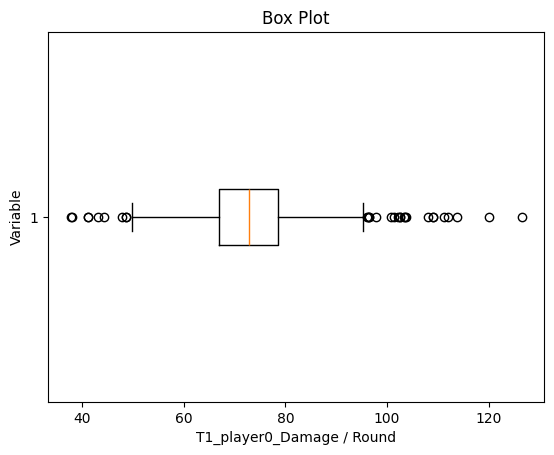

In [12]:
import matplotlib.pyplot as plt

# Проверяем распределение урона за раунд
plt.boxplot(df1['T1_player0_Damage / Round'].dropna(), vert=False)
plt.ylabel('Variable')
plt.xlabel('T1_player0_Damage / Round')
plt.title('Box Plot')
plt.show()

In [13]:
# Заменяем бесконечные значения пропусками
df1 = df1.replace([np.inf, -np.inf], np.nan)

# Удаляем строки с пропущенными значениями
df1 = df1.dropna()

# Проверяем результат очистки
print('Размер таблицы после очистки:', df1.shape)
print('Количество пропусков:', df1.isnull().sum().sum())
print('Количество дубликатов:', df1.duplicated().sum())

Размер таблицы после очистки: (1009, 147)
Количество пропусков: 0
Количество дубликатов: 0


Удалён один полный дубликат, исключены 11 столбцов, преобразованы числовые показатели, записанные текстом. Удалены 192 строки с пропусками. Подготовленная таблица содержит 1009 наблюдений и 147 столбцов, пропуски и полные дубликаты отсутствуют. Значения за пределами усов сохранены, поскольку их ошибочность не установлена.

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


Размерность данных: (1009, 147)
Пропуски по столбцам:
 matchID                               0
team1                                 0
team2                                 0
map                                   0
team1_win                             0
                                     ..
T2_player4_Saved teammates / round    0
T2_player4_Rating 2.0                 0
T1_player1_Rating 2.0                 0
T1_player0_Rating 2.0                 0
T2_player0_Rating 2.0                 0
Length: 147, dtype: int64

Описательная статистика:
           matchID  team1_win  T1_mapwinrate  T2_mapwinrate  \
count     1009.00    1009.00        1009.00        1009.00   
mean   2368723.97       0.54          46.82          43.97   
std        380.17       0.50          24.15          25.16   
min    2366907.00       0.00           0.00           0.00   
25%    2368461.00       0.00          33.30          28.60   
50%    2368709.00       1.00          50.00          50.00   
75%    2369029.00 

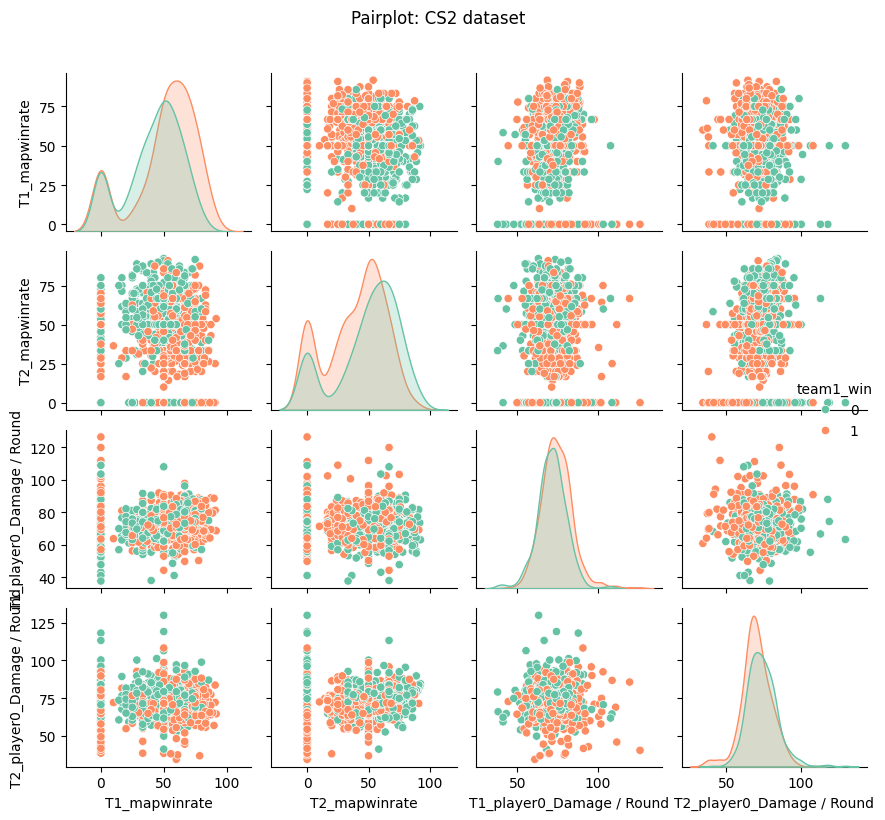

In [15]:
# Проверяем размерность и пропуски
print("Размерность данных:", df1.shape)
print("Пропуски по столбцам:\n", df1.isna().sum())

# Выводим описательную статистику
print("\nОписательная статистика:\n", df1.describe().round(2))

# Визуализация распределений и попарных связей
sns.pairplot(
    df1[['T1_mapwinrate', 'T2_mapwinrate',
         'T1_player0_Damage / Round', 'T2_player0_Damage / Round',
         'team1_win']],
    hue='team1_win',
    palette='Set2',
    diag_kind='kde',
    height=2.0
)
plt.suptitle("Pairplot: CS2 dataset", y=1.02)
plt.tight_layout()
plt.show()

In [16]:
# Выбираем признаки и целевую переменную
X = df1.drop(columns=['matchID', 'team1', 'team2', 'map', 'team1_win'])
y = df1['team1_win']

# Отдельная тестовая выборка не участвует в подборе k
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)
print('Обучающая выборка:', X_train.shape)
print('Тестовая выборка:', X_test.shape)


Обучающая выборка: (706, 142)
Тестовая выборка: (303, 142)


Данные разделены в пропорции 70/30 с сохранением пропорций классов. Стандартизация будет выполняться внутри Pipeline отдельно для каждой обучающей части кросс-валидации.


In [17]:
from sklearn.pipeline import Pipeline

# Подбираем число соседей: scaler обучается отдельно внутри каждого разбиения
cv_scores = []
k_range = range(1, 31)
for k in k_range:
    model = Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=k))
    ])
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')
    cv_scores.append(scores.mean())

best_k = k_range[int(np.argmax(cv_scores))]
print(f'Оптимальное k = {best_k} (CV accuracy = {max(cv_scores):.4f})')

# Итоговая модель: стандартизация обучается на всей обучающей выборке
knn_final = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=best_k))
])
knn_final.fit(X_train, y_train)


Оптимальное k = 27 (CV accuracy = 0.6799)


Pipeline(steps=[('scaler', StandardScaler()),
                ('knn', KNeighborsClassifier(n_neighbors=27))])

Сравниваются значения k от 1 до 30 по средней точности пятикратной кросс-валидации. Выбранное k и оценка выводятся после выполнения ячейки.


Accuracy на тесте: 0.7261
                          precision    recall  f1-score   support

Поражение первой команды       0.78      0.57      0.66       140
   Победа первой команды       0.70      0.86      0.77       163

                accuracy                           0.73       303
               macro avg       0.74      0.72      0.71       303
            weighted avg       0.74      0.73      0.72       303



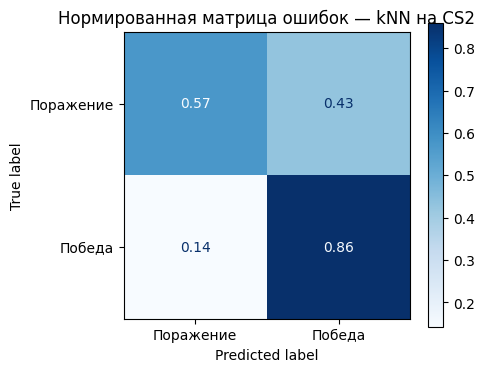

In [18]:
# Pipeline сам применяет стандартизацию к тестовым данным
y_pred = knn_final.predict(X_test)
print('Accuracy на тесте:', round(accuracy_score(y_test, y_pred), 4))
print(classification_report(
    y_test, y_pred, labels=[0, 1],
    target_names=['Поражение первой команды', 'Победа первой команды'],
    zero_division=0
))
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_estimator(
    knn_final, X_test, y_test, labels=[0, 1],
    display_labels=['Поражение', 'Победа'], cmap='Blues',
    ax=ax, normalize='true'
)
ax.set_title('Нормированная матрица ошибок — kNN на CS2')
plt.tight_layout()
plt.show()


Качество на отдельной тестовой выборке оценивается после выбора k. В отчёте показаны precision, recall и F1 для каждого класса; матрица ошибок нормирована по строкам.


После очистки осталось 1009 наблюдений. Для классификации использованы 142 числовых признака. Стандартизация и kNN объединены в Pipeline. По пятикратной кросс-валидации выбрано k = 27, средняя точность - 68,0%. На 303 тестовых наблюдениях точность составила 72,6%. Модель лучше распознаёт победы первой команды: полнота - 86%, для поражений - 57%. Результат относится к учебному эксперименту, возможность прогнозирования будущих матчей отдельно не проверялась.